# 03: The efficient frontier

Players are assets. Expected VAEP/90 is the return, the weekly wage is the cost, and the squad is a binary portfolio: you either sign the player or you do not. For each wage budget, integer programming finds the 23-man squad with maximum expected value. Plot budget against value and you get the efficient frontier.

In [1]:
import pickle, os, numpy as np, pandas as pd
from effc.data.download import DATA_DIR
from effc.data.wages import load_wages, match_players
from effc.ratings.ratings import build_ratings

pm, mins, matches = pickle.load(open(os.path.join(DATA_DIR, 'cache', 'target_vaep.pkl'), 'rb'))
wmap = match_players(pm[['player','team']].drop_duplicates().reset_index(drop=True), load_wages())
ratings = build_ratings(pm, mins, wmap, min_minutes=90, shrink_k=900)
print(f"{len(ratings)} rated players, wage match {wmap['matched'].mean():.1%}")
print(ratings.nlargest(10, 'vaep_per90')[['player','team','pos_group','vaep_per90','wage_eur']].to_string(index=False))

268 rated players, wage match 63.2%
                   player             team pos_group  vaep_per90  wage_eur
           Oliver Baumann       Hoffenheim        GK    0.670273   34000.0
            Florian Wirtz Bayer Leverkusen       MID    0.666048   77000.0
       Christian Mathenia     Darmstadt 98        GK    0.658003    4000.0
         Jeremie Frimpong Bayer Leverkusen       DEF    0.606326   63000.0
          Alexander Nübel    VfB Stuttgart        GK    0.597125   45000.0
Alejandro Grimaldo García Bayer Leverkusen       DEF    0.578349   88000.0
             Ja-Cheol Koo         Augsburg       MID    0.568831    2000.0
               Bernd Leno Bayer Leverkusen        GK    0.546597   76000.0
             Granit Xhaka Bayer Leverkusen       MID    0.528850   74000.0
            Julian Brandt Bayer Leverkusen       MID    0.528105   72000.0


Raw per-90 numbers are shrunk toward position-group means: 90 minutes of brilliance does not make you the best player in the league. Wirtz on top is no surprise. The interesting names are the cheap ones next to him.

   budget  exp_vaep_per90  wage_bill
 300000.0       10.551976   299250.0
 500000.0       11.321473   498750.0
 700000.0       11.791870   699000.0
 943000.0       12.019221   923000.0
1500000.0       12.060347  1046000.0


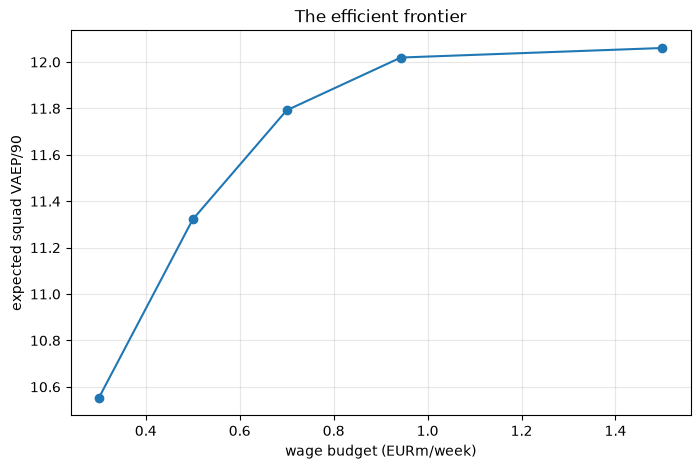

In [2]:
from effc.portfolio.portfolio import efficient_frontier, select_squad, select_xi

budgets = np.array([300_000, 500_000, 700_000, 943_000, 1_500_000], dtype=float)
fr = efficient_frontier(ratings, budgets)
print(fr[['budget','exp_vaep_per90','wage_bill']].to_string(index=False))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(fr['budget']/1e6, fr['exp_vaep_per90'], marker='o')
ax.set_xlabel('wage budget (EURm/week)'); ax.set_ylabel('expected squad VAEP/90')
ax.set_title('The efficient frontier')
ax.grid(alpha=0.3); plt.show()

Diminishing returns, then a flat top. Past about 0.94M/week the budget stops binding: the unconstrained best 23 costs that much, and money cannot buy more VAEP in this player pool. That flat top is itself a result. It says the best squad here is a Moneyball squad, not a galactico squad.

In [3]:
xi = select_xi(select_squad(ratings, 943_000), formation='4-3-3')
print(xi[['player','team','pos_group','vaep_per90','wage_eur']].to_string(index=False))
print('\nXI wage bill: EUR', f"{xi['wage_eur'].sum():,.0f}", '/week')

                   player              team pos_group  vaep_per90  wage_eur
             Granit Xhaka  Bayer Leverkusen       MID    0.528850   74000.0
Pierre-Emerick Aubameyang Borussia Dortmund       FWD    0.463235   54000.0
             Ja-Cheol Koo          Augsburg       MID    0.568831    2000.0
            Patrik Schick  Bayer Leverkusen       FWD    0.440382   73000.0
           Oliver Baumann        Hoffenheim        GK    0.670273   34000.0
Alejandro Grimaldo García  Bayer Leverkusen       DEF    0.578349   88000.0
             Manuel Gulde          Freiburg       DEF    0.420218   20000.0
         Jeremie Frimpong  Bayer Leverkusen       DEF    0.606326   63000.0
               Amine Adli  Bayer Leverkusen       FWD    0.506427   45000.0
            Florian Wirtz  Bayer Leverkusen       MID    0.666048   77000.0
           Josip Stanišić  Bayer Leverkusen       DEF    0.470709   41000.0

XI wage bill: EUR 571,000 /week


That XI costs under a million a week and is nine unbeaten-championship players plus two value picks. Whether you buy that it would win the league is a different question, and it is exactly what the next notebook tests.